In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from DecisionPolicy import *
from loading_utils import *
from viz_utils import *

sns.set_style('darkgrid')
plt.rcParams.update({'font.size': 8,
                     'xtick.labelsize': 7,
                     'ytick.labelsize': 7,
                     'axes.labelsize': 8,
                     'axes.titlesize': 10})

## 1a. Select the model configuration & load the data from the trained model
The allowable options for the model configuration are:
- Model: `logistic`, `knn`, `xgb`
- Embedding: `e5`, `tfidf`
- Splitting: `calibration`, `validation`
- Score type: `expected`, `hard`

In [2]:
# select output to load from trained model
model_name = 'xgb'
embed_name = 'e5'
split_name = 'validation'
score_type = 'expected'

scores, costs = load_predictions(model_name, embed_name, split_name, score_type)
predictions   = (scores, costs)

print(f'Score data type: {type(scores)}, \t Score data shape: {scores.shape}')
print(f'Cost data type: {type(costs)}, \t Cost data shape: {costs.shape}')

Score data type: <class 'pandas.DataFrame'>, 	 Score data shape: (3649, 11)
Cost data type: <class 'pandas.DataFrame'>, 	 Cost data shape: (3649, 11)


## 1b. Load the ground truth
Use `load_split()` from `1_data_preparation/` to load the prompts, true scores, and true costs.

In [3]:
# load the questions, scores, and costs from the validation set
_, Q, S, C = load_split(split_name)
truths = (S, C)

validation Features: (3649, 388) Scores: (3649, 11)


## 1c. Prediction data analysis
This section creates figures and tables to visualize the following statistics.
1. Predicted vs actual scores for each LLM.
2. Residuals for each LLM.
3. The mean residual & mean absolute error for scores and the mean average percentage error for costs.
$$p_i = \text{true score}, \quad \hat{p}_i = \text{predicted score}$$
$$c_i = \text{true cost}, \quad \hat{c}_i = \text{predicted cost}$$
$$\text{Mean residual error} = \frac{1}{n} \sum_{i=1}^n (p_i-\hat{p}_i)$$
$$\text{Mean absolute error} = \frac{1}{n} \sum_{i=1}^n |p_i-\hat{p}_i|$$
$$\text{Mean absolute percentage error} = 100 \times \Bigg( \frac{1}{n} \sum_{i=1}^n \frac{|c_i-\hat{c}_i|}{c_i} \Bigg) \%$$

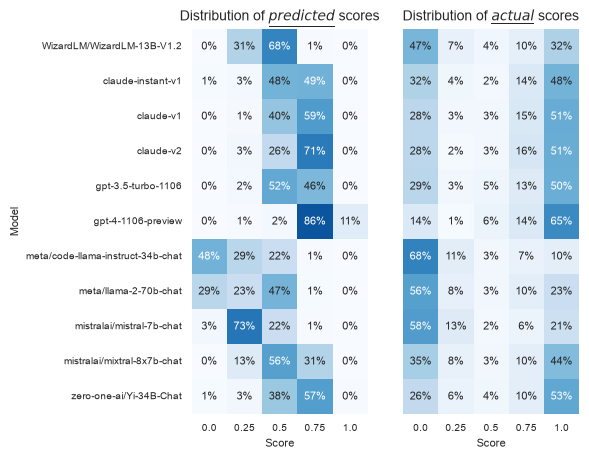

In [4]:
binned_model_preds = get_bin_counts(scores, normal=True)
binned_model_scores = get_bin_counts(S)
fig = heatmap_comparison(binned_model_preds, binned_model_scores)

In [5]:
errors = pd.DataFrame(abs(S-scores).mean(axis=0), columns=["Score MAE"])
errors["Score MR"] = (S-scores).mean(axis=0)
errors["Cost MAPE"] = (100 * abs(C-costs) / costs).mean(axis=0).map('{:,.2f}%'.format)
errors.sort_values(by="Score MAE")

,Score MAE,Score MR,Cost MAPE
meta/code-llama-instruct-34b-chat,0.197273,0.002064,8.86%
gpt-4-1106-preview,0.245836,0.005602,13.39%
meta/llama-2-70b-chat,0.288201,0.011060,8.79%
mistralai/mistral-7b-chat,0.342602,-0.003718,11.48%
zero-one-ai/Yi-34B-Chat,0.347196,-0.003164,10.85%
claude-v2,0.371416,0.014404,10.23%
claude-v1,0.375419,0.012515,11.20%
gpt-3.5-turbo-1106,0.377203,0.009457,10.72%
mistralai/mixtral-8x7b-chat,0.389827,0.005769,9.26%
claude-instant-v1,0.393861,0.006167,10.88%


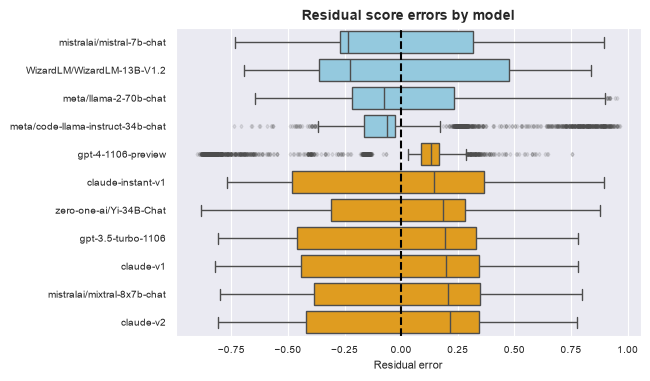

In [6]:
residuals = S-scores
medians   = residuals.median()

# sort by median value
index_sort = medians.sort_values().index
sorted_residuals = residuals[index_sort]

# assign colors based on the median sign
colors = medians.map(
    lambda r: "skyblue" if r < 0 else "orange"
).to_dict()

plt.figure(figsize=(6,4))
sns.boxplot(sorted_residuals, orient='h', palette=colors,
            fliersize=2, flierprops={"marker": "d", "alpha": 0.2},)
plt.axvline(x=0, c='k', linestyle='--')
plt.xlabel('Residual error')
plt.title('Residual score errors by model', fontweight="bold")
plt.show()

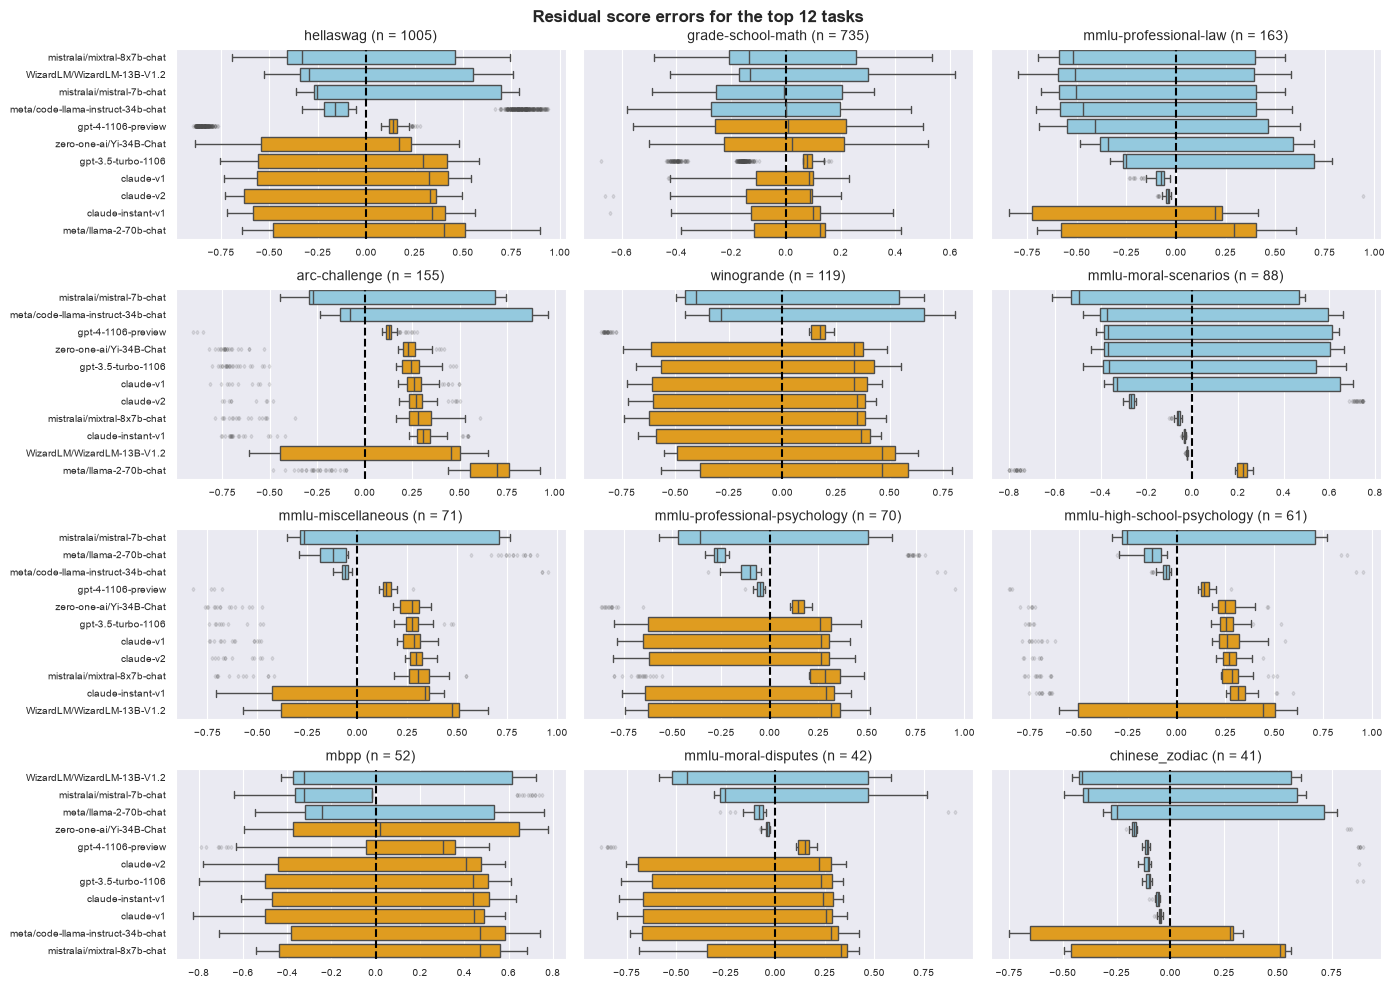

In [7]:
num_tasks = 12
tasks, _ = get_top_tasks(Q, num=num_tasks)
tasks    = tasks.index.to_list()
labeled_residuals = residuals.join(Q["eval_name"], how="left")

fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(14,10))
axs = axs.flatten()

for i in range(num_tasks):
    t = tasks[i]
    task_res = labeled_residuals[labeled_residuals["eval_name"] == t]
    task_med = task_res.iloc[:, :-1].median()
    
    # sort by median value
    index_sort = task_med.sort_values().index
    sorted_res = task_res[index_sort]
    
    # assign colors based on the median sign
    colors = task_med.map(
        lambda r: "skyblue" if r < 0 else "orange"
    ).to_dict()

    ax = axs[i]
    sns.boxplot(data=sorted_res, ax=ax, orient='h', palette=colors,
                fliersize=2, flierprops={"marker": "d", "alpha": 0.2},)
    
    if i % 3 != 0:
        ax.set_yticklabels([])
        
    ax.axvline(x=0, c='k', linestyle='--')
    ax.set_title(f'{t} (n = {len(task_res)})')

plt.suptitle(f'Residual score errors for the top {num_tasks} tasks', 
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 2. Implement the decision policy

The **model score** of model $m$ on prompt $x$ is defined to be
$$S_m(x;\lambda) = \hat{p}_m(x) - \lambda\hat{c}_m(x),$$
where:
- $\hat{p}_m(x)$ is the predicted score of model $m$ on prompt $x$
- $\hat{c}_m(x)$ is the predicted cost of model $m$ on prompt $x$
- $\lambda\geq 0$ represents **willingness to pay**:
  - $\lambda=0$ favors the highest-scoring model
  - $\lambda\gg 0$ penalizes expensive models

For a given prompt $x$, our **decision policy** is to select the model with the highest model score.
$$\mu_\lambda(x) = \underset{m=1,\ldots,M}{\text{argmin}} S_m(x;\lambda), \quad x\in\text{Val}$$

The policy outcome for a given $\lambda$ is measured by computing the average score and cost over the validation set.
$$\text{Per}(\lambda) = \frac{1}{|\text{Val}|} \sum_{x\in\text{Val}} p_{\mu_\lambda(x)}(x), \quad \text{Cost}(\lambda) = \frac{1}{|\text{Val}|} \sum_{x\in\text{Val}} c_{\mu_\lambda(x)}(x)$$
We emphasize here that $\text{Per}, \text{Cost}$ are computed from the *true* outcome after selecting the model according to the decision policy. 

The **oracle policy** selects the highest performing model for each prompt $x$:
$$o(x) = \underset{m=1,\ldots,M}{\text{argmax}} p_m(x)$$

## 2a. Inspecting the decision policy for a single $\lambda$
The policy is implemented through the `DecisionPolicy` class. After instantiating with a value of `l`, the models selected by the policy are stored in the `.selected_models` attribute. The other relevant metrics may be accessed by:
- `.policy_performance`: the computed value of $\text{Per}(\lambda)$
- `.policy_cost`: the computed value of $\text{Cost}(\lambda)$
- `.evaluate_lambda(l)`: evaluate the policy for any value of `l`
- `.evaluate_lambdas(l_values, batch_size)`: evaluate the policy for a list of `l`'s.
    - `batch_size` is an optional parameter for controlling memory consumption in the vectorized computation. The default value is `len(l_values)`.

In [8]:
%%time
# instantiate a class to analyze the prediction results using lambda = 0.1
policy = DecisionPolicy(
    predictions,
    truths,
    l=0.1,
    show=True
)

===========Statistics for l=0.1===========

Number of times each model was selected:


best_model
gpt-4-1106-preview                   2982
claude-v2                             416
claude-v1                             141
zero-one-ai/Yi-34B-Chat                42
mistralai/mixtral-8x7b-chat            41
meta/code-llama-instruct-34b-chat      13
gpt-3.5-turbo-1106                     12
claude-instant-v1                       2
Name: count, dtype: int64

Performance: 0.790737
Cost: $0.002757
CPU times: user 8.45 ms, sys: 17 μs, total: 8.47 ms
Wall time: 7.82 ms


In [9]:
# compute some error metrics for the top 10 tasks
policy.evaluate_top_tasks(Q)

,Count,Score MR,Score MAE,Cost MAPE
Task,,,,
hellaswag,1005,-0.010924,0.260368,5.70%
grade-school-math,735,0.010749,0.119611,13.55%
mmlu-professional-law,163,-0.101204,0.408150,8.36%
arc-challenge,155,0.112644,0.146685,13.84%
winogrande,119,-0.042328,0.328747,32.18%
mmlu-moral-scenarios,88,0.004343,0.353032,8.24%
mmlu-miscellaneous,71,0.102763,0.185845,15.67%
mmlu-professional-psychology,70,-0.036827,0.288876,12.37%
mmlu-high-school-psychology,61,0.099399,0.183060,11.48%


In [10]:
# example use of evaluate_lambda method to evaluate the policy for a different lambda
per, cost = policy.evaluate_lambda(1000)

print(f"Performance: {per:.4f}")
print(f"Cost: ${cost:.6f}")

Performance: 0.6574
Cost: $0.000130


## 3a. The cost-performance curve
Take a log-uniform grid $\lambda_1, \ldots, \lambda_n$ and set $\lambda_0=0$. Compute their associated accuracies and costs:
$$\text{Cost}(\lambda_0), \text{Cost}(\lambda_1), \ldots, \text{Cost}(\lambda_n)$$
$$\text{Acc}(\lambda_0), \text{Acc}(\lambda_1), \ldots, \text{Acc}(\lambda_n)$$
The resulting graph of $(\text{Cost},\text{Acc})$ represents the **cost-performance** tradeoff obtained by decreasing the willingness to pay.

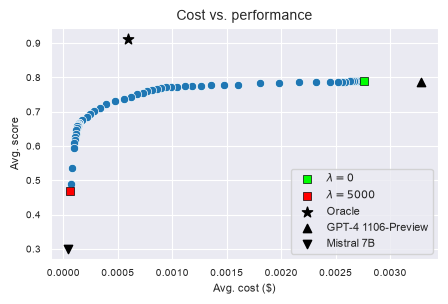

In [11]:
l_max = 5000
L = np.concatenate([[0],np.geomspace(0.001, l_max, 100)])
analysis = DecisionPolicy(predictions, truths, l=0, show=False)
results = policy.evaluate_lambdas(L, batch_size=20)

# compute oracle
oracle_idx = S.idxmax(axis=1)
oracle_idx = S.columns.get_indexer(oracle_idx)
oracle_scores = S.max(axis=1)
oracle_costs = C.to_numpy()[np.arange(len(C)), oracle_idx]

os = oracle_scores.mean()
oc = oracle_costs.mean()

# compute gpt
gs = S['gpt-4-1106-preview'].mean()
gc = C['gpt-4-1106-preview'].mean()

# compute mistral
ms = S['mistralai/mistral-7b-chat'].mean()
mc = C['mistralai/mistral-7b-chat'].mean()

# plot cost vs accuracy
plt.figure(figsize=(5,3))

sns.scatterplot(results, x='cost', y='performance')
sns.scatterplot(results[results.index == 0], x='cost', y='performance',
                c='lime', edgecolors='k', marker='s', label=r'$\lambda=0$')
sns.scatterplot(results[results.index == l_max], x='cost', y='performance', 
                c='r', edgecolors='k', marker='s', label=r'$\lambda='+str(l_max)+'$')

# plot reference points
plt.scatter(oc, os, color='k', marker='*', s=60, label='Oracle')
plt.scatter(gc, gs, color='k', marker='^', label='GPT-4 1106-Preview')
plt.scatter(mc, ms, color='k', marker='v', label='Mistral 7B')

plt.title('Cost vs. performance')
plt.xlabel('Avg. cost ($)')
plt.ylabel('Avg. score')
plt.legend()
plt.show()

## 3b. Fitting the cost-performance curve with an exponential
The cost-performance curve appears to be monotonically increasing. Fit it with an exponential curve of the form
$$\gamma(c) = a + b\Bigg[ 1 - \exp\Bigg(-\frac{(c-c_\text{min})^p}{\tau}\Bigg) \Bigg]$$

In [12]:
from scipy.optimize import curve_fit

x = results["cost"].to_numpy() * 1000  # Convert to millidollars
y = results["performance"].to_numpy()
x0 = x.min()

def fitting_curve(x, a, b, tau, p):
    z = np.maximum(x - x0, 0)
    return a + b * (1 - np.exp(-z**p / tau))

def inverse_fitting_curve(y, a, b, tau, p):
    z = np.maximum(x - x0, 0)
    return x0 + (tau * np.log(b / (a + b - y))) ** (1/p)

params, _ = curve_fit(
    fitting_curve,
    x,
    y,
    p0=[y.min(), y.max() - y.min(), 0.5, 0.5],
    bounds=([0, 0, 1e-8, 0.01], [1, 1, np.inf, 1]),
    maxfev=20000
)

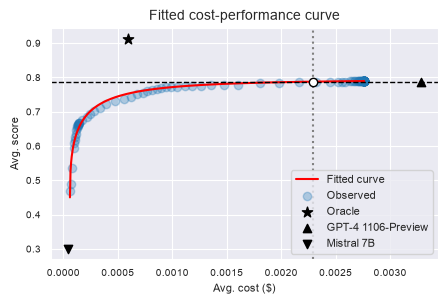

The fitted cost $0.002293 corresponds to a -30.08% change compared to GPT-4.
The cheapest lambda achieving the minimum performance is: l = 3.3010409462330443


In [13]:
# Set the performance threshold. Default value = GPT
T = gs

# find the associated cost using the inverse curve
inv_T = inverse_fitting_curve(T, *params) / 1000

# plot fitted curve
x_fit = np.linspace(x.min(), x.max(), 500)
y_fit = fitting_curve(x_fit, *params)

plt.figure(figsize=(5,3))
plt.plot(x_fit / 1000, y_fit, 'r', label="Fitted curve")
plt.scatter(x / 1000, y, label="Observed", alpha=0.3)

# plot reference points
plt.scatter(oc, os, color='k', marker='*', s=60, label='Oracle')
plt.scatter(gc, gs, color='k', marker='^', label='GPT-4 1106-Preview')
plt.scatter(mc, ms, color='k', marker='v', label='Mistral 7B')

# plot tolerance line
plt.axhline(y=T, color='k', linestyle='--', lw=1)
plt.axvline(x=inv_T, color='gray', linestyle=':')
plt.scatter(inv_T, T, color='w', edgecolors='k', zorder=2)

plt.title('Fitted cost-performance curve')
plt.xlabel("Avg. cost ($)")
plt.ylabel("Avg. score")
plt.legend()
plt.show()

# find the closest lambda that achieves the minimum tolerance for the cheapest ccost
l_T = policy.select_lambda_from_threshold(l_values=L, threshold=T, batch_size=20)

print(f'The fitted cost ${inv_T:0.6f} corresponds to a {100*(gc-inv_T)/gc*np.sign(inv_T-gc):0.2f}% change compared to GPT-4.')
print(f'The cheapest lambda achieving the minimum performance is: l = {l_T}')